<a href="https://colab.research.google.com/github/routparam12/Python_qns/blob/main/Image_classification_using_transfer_learning_in_pytorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Import Dependencies

In [1]:
!pip install torchinfo -q

In [2]:
import torch  # Import PyTorch for deep learning computations
import torchvision  # Import torchvision for pre-trained models and datasets
import torch.nn as nn  # Import neural network module from PyTorch
import torch.optim as optim  # Import optimizers for training models
import time  # Import time module for measuring execution time
import numpy as np  # Import NumPy for numerical operations
import matplotlib.pyplot as plt  # Import Matplotlib for visualization
import os  # Import os for file system operations
import zipfile  # Import zipfile for extracting compressed datasets
import requests  # Import requests for downloading files

import pandas as pd  # Import pandas for data manipulation and analysis
from PIL import Image  # Import PIL for image processing
from torchvision import datasets, models, transforms  # Import datasets, pre-trained models, and transformations from torchvision
from torchinfo import summary  # Import torchinfo for displaying model summaries
from torch.utils.data import DataLoader  # Import DataLoader for handling batch data loading

plt.style.use('ggplot')  # Set the Matplotlib style to 'ggplot' for better visuals

## 2. Download and Extract the Caltech256 Subset Dataset

In [3]:
# Helper function to download file.
def download_file(url, save_name):
    url = url
    if not os.path.exists(save_name):
        file = requests.get(url)
        open(save_name, 'wb').write(file.content)

In [4]:
# Download the dataset.
download_file(
    'https://www.dropbox.com/s/0ltu2bsja3sb2j4/caltech256_subset.zip?dl=1',
    'caltech256_subset.zip'
)

In [5]:
# Extract the dataset.
file = 'caltech256_subset.zip'
with zipfile.ZipFile(file, 'r') as zip:
    # extract all files
    print('extraction...')
    zip.extractall()
    print('Done!')

extraction...
Done!


## 3. DataLoader Preparation

The dataset we will be using here is a subset of Caltech256 dataset
 containing 10 categories and number of samples as follows:

|     Class     | Train Samples | Valid Samples | Test Samples |
|:-------------:|:-------------:|:-------------:|:------------:|
|      bear     |       60      |       10      |      10      |
|     chimp     |       60      |       10      |      10      |
|    giraffe    |       60      |       10      |      10      |
|    gorilla    |       60      |       10      |      10      |
|     llama     |       60      |       10      |      10      |
|    ostrich    |       60      |       10      |      10      |
|   porcupine   |       60      |       10      |      10      |
|     skunk     |       60      |       10      |      10      |
| triceratops   |       60      |       10      |      10      |
|     zebra     |       60      |       10      |      10      |


3.1. Preprocessing Transforms

In [6]:
# Defining transformations to be applied to training, validation, and test datasets
image_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(size=256, scale=(0.8, 1.0)),  # Randomly crop the image with scaling
        transforms.RandomRotation(degrees=15),  # Apply random rotation up to 15 degrees
        transforms.RandomHorizontalFlip(),  # Flip the image horizontally with a probability of 0.5
        transforms.CenterCrop(size=224),  # Crop the center of the image to 224x224 pixels
        transforms.ToTensor(),  # Convert image to PyTorch tensor format
        transforms.Normalize([0.485, 0.456, 0.406],  # Normalize image using mean
                             [0.229, 0.224, 0.225])  # Normalize image using std deviation
    ]),
    'valid': transforms.Compose([
        transforms.Resize(size=256),  # Resize the image to 256 pixels on the shorter side
        transforms.CenterCrop(size=224),  # Crop the center of the image to 224x224 pixels
        transforms.ToTensor(),  # Convert image to PyTorch tensor format
        transforms.Normalize([0.485, 0.456, 0.406],  # Normalize image using mean
                             [0.229, 0.224, 0.225])  # Normalize image using std deviation
    ]),
    'test': transforms.Compose([
        transforms.Resize(size=256),  # Resize the image to 256 pixels on the shorter side
        transforms.CenterCrop(size=224),  # Crop the center of the image to 224x224 pixels
        transforms.ToTensor(),  # Convert image to PyTorch tensor format
        transforms.Normalize([0.485, 0.456, 0.406],  # Normalize image using mean
                             [0.229, 0.224, 0.225])  # Normalize image using std deviation
    ])
}


3.2. Dataset Preparation

In [7]:
# Load the Data

# Set train and valid directory paths

dataset = 'caltech256_subset'

train_directory = os.path.join(dataset, 'train')
valid_directory = os.path.join(dataset, 'valid')
test_directory = os.path.join(dataset, 'test')

# Batch size
batch_size = 32

# Number of classes
num_classes = len(os.listdir(valid_directory))  #10#2#257
print(num_classes)

# Load Data from folders
data = {
    'train': datasets.ImageFolder(root=train_directory, transform=image_transforms['train']),
    'valid': datasets.ImageFolder(root=valid_directory, transform=image_transforms['valid']),
    'test': datasets.ImageFolder(root=test_directory, transform=image_transforms['test'])
}

# Get a mapping of the indices to the class names, in order to see the output classes of the test images.
idx_to_class = {v: k for k, v in data['train'].class_to_idx.items()}
print(idx_to_class)

# Size of Data, to be used for calculating Average Loss and Accuracy
train_data_size = len(data['train'])
valid_data_size = len(data['valid'])
test_data_size = len(data['test'])

# Create iterators for the Data loaded using DataLoader module
train_data_loader = DataLoader(data['train'], batch_size=batch_size, shuffle=True)
valid_data_loader = DataLoader(data['valid'], batch_size=batch_size, shuffle=False)
test_data_loader = DataLoader(data['test'], batch_size=batch_size, shuffle=False)

10
{0: 'bear', 1: 'chimp', 2: 'giraffe', 3: 'gorilla', 4: 'llama', 5: 'ostrich', 6: 'porcupine', 7: 'skunk', 8: 'triceratops', 9: 'zebra'}


In [8]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print(f"Number of training samples:   {train_data_size}")
print(f"Number of validation samples: {valid_data_size}"),
print(f"Number of test samples:       {test_data_size}")

Number of training samples:   600
Number of validation samples: 100
Number of test samples:       100


## 4. Load the **ResNet50** Pre-Trained Model

In [9]:
# Load pretrained ResNet50 Model
resnet50 = models.resnet50(weights='DEFAULT')
resnet50 = resnet50.to(device)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 132MB/s]


4.1. Set all the layers to be freezed initially
By setting the param.requires_grad = False we ensure that all the model weights for those layers are freezed.

In [10]:
# Freeze model parameters
for param in resnet50.parameters():
    param.requires_grad = False

### 4.2. Unfreeze the final layer of the classifier's head

As our dataset contains just 10 classes we have to modify the model's final layer from IMAGENET 1000 classes to match the num of classes of the subset dataset.

In [11]:
# Change the final fully connected layer of the ResNet50 model for transfer learning
fc_inputs = resnet50.fc.in_features  # Get the number of input features for the final layer

# Define a new fully connected layer with custom architecture for classification
resnet50.fc = nn.Sequential(
    nn.Linear(fc_inputs, 256),  # Fully connected layer with 256 neurons
    nn.ReLU(),  # Apply ReLU activation
    nn.Dropout(0.4),  # Apply dropout with 40% probability to prevent overfitting
    nn.Linear(256, num_classes),  # Output layer with number of classes as output neurons
    nn.LogSoftmax(dim=1)  # Apply LogSoftmax for multi-class classification (used with NLLLoss)
)

# Move the model to the appropriate device (either CUDA or CPU)
resnet50 = resnet50.to(device)

### 4.3. Training Configuration

In [12]:
# Define the loss function for classification
loss_func = nn.NLLLoss()  # NLLLoss is suitable for multi-class classification

# Define the learning rate for the optimizer
learning_rate = 0.01  # Initial learning rate for the optimizer

# Define the optimizer using Stochastic Gradient Descent (SGD)
optimizer = optim.SGD(
    params=resnet50.parameters(),  # Optimizing all parameters of the ResNet50 model
    lr=learning_rate,  # Learning rate value
    momentum=0.9  # Momentum term to improve convergence and avoid local minima
)

5. Model Training

In [13]:
def train_and_validate(model, loss_criterion, optimizer, epochs=25):
    """
    Function to train and validate
    Parameters
        :param model: Model to train and validate
        :param loss_criterion: Loss Criterion to minimize
        :param optimizer: Optimizer for computing gradients
        :param epochs: Number of epochs (default=25)

    Returns
        model: Trained Model with best validation accuracy
        history: (dict object): Having training loss, accuracy and validation loss, accuracy
    """

    start = time.time()
    history = []
    best_loss = 100000.0
    best_epoch = None

    for epoch in range(epochs):
        epoch_start = time.time()
        print("Epoch: {}/{}".format(epoch+1, epochs))

        # Set to training mode
        model.train()

        # Loss and Accuracy within the epoch
        train_loss = 0.0
        train_acc = 0.0

        valid_loss = 0.0
        valid_acc = 0.0

        for i, (inputs, labels) in enumerate(train_data_loader):

            inputs = inputs.to(device)
            labels = labels.to(device)

            # Clean existing gradients
            optimizer.zero_grad()

            # Forward pass - compute outputs on input data using the model
            outputs = model(inputs)

            # Compute loss
            loss = loss_criterion(outputs, labels)

            # Backpropagate the gradients
            loss.backward()

            # Update the parameters
            optimizer.step()

            # Compute the total loss for the batch and add it to train_loss
            train_loss += loss.item() * inputs.size(0)

            # Compute the accuracy
            ret, predictions = torch.max(outputs.data, 1)
            correct_counts = predictions.eq(labels.data.view_as(predictions))

            # Convert correct_counts to float and then compute the mean
            acc = torch.mean(correct_counts.type(torch.FloatTensor))

            # Compute total accuracy in the whole batch and add to train_acc
            train_acc += acc.item() * inputs.size(0)

            #print("Batch number: {:03d}, Training Loss: {:.4f}, Accuracy: {:.4f}".format(i, loss.item(), acc.item()))


        # Validation - No gradient tracking needed
        with torch.no_grad():

            # Set to evaluation mode
            model.eval()

            # Validation loop
            for j, (inputs, labels) in enumerate(valid_data_loader):
                inputs = inputs.to(device)
                labels = labels.to(device)

                # Forward pass - compute outputs on input data using the model
                outputs = model(inputs)

                # Compute loss
                loss = loss_criterion(outputs, labels)

                # Compute the total loss for the batch and add it to valid_loss
                valid_loss += loss.item() * inputs.size(0)

                # Calculate validation accuracy
                ret, predictions = torch.max(outputs.data, 1)
                correct_counts = predictions.eq(labels.data.view_as(predictions))

                # Convert correct_counts to float and then compute the mean
                acc = torch.mean(correct_counts.type(torch.FloatTensor))

                # Compute total accuracy in the whole batch and add to valid_acc
                valid_acc += acc.item() * inputs.size(0)

                #print("Validation Batch number: {:03d}, Validation: Loss: {:.4f}, Accuracy: {:.4f}".format(j, loss.item(), acc.item()))
        if valid_loss < best_loss:
            best_loss = valid_loss
            best_epoch = epoch
            # Save if the model has best accuracy till now
            torch.save(model, 'best_model.pt')

        # Find average training loss and training accuracy
        avg_train_loss = train_loss/train_data_size
        avg_train_acc = train_acc/train_data_size

        # Find average training loss and training accuracy
        avg_valid_loss = valid_loss/valid_data_size
        avg_valid_acc = valid_acc/valid_data_size

        history.append([avg_train_loss, avg_valid_loss, avg_train_acc, avg_valid_acc])

        epoch_end = time.time()

        print("Epoch : {:03d}, Training: Loss - {:.4f}, Accuracy - {:.4f}%, \n\t\tValidation : Loss - {:.4f}, Accuracy - {:.4f}%, Time: {:.4f}s".format(epoch, avg_train_loss, avg_train_acc*100, avg_valid_loss, avg_valid_acc*100, epoch_end-epoch_start))




    return model, history, best_epoch


In [14]:
# Print the model to be trained.
print(summary(resnet50, input_size=(batch_size, 3, 224, 224)))

Layer (type:depth-idx)                   Output Shape              Param #
ResNet                                   [32, 10]                  --
├─Conv2d: 1-1                            [32, 64, 112, 112]        (9,408)
├─BatchNorm2d: 1-2                       [32, 64, 112, 112]        (128)
├─ReLU: 1-3                              [32, 64, 112, 112]        --
├─MaxPool2d: 1-4                         [32, 64, 56, 56]          --
├─Sequential: 1-5                        [32, 256, 56, 56]         --
│    └─Bottleneck: 2-1                   [32, 256, 56, 56]         --
│    │    └─Conv2d: 3-1                  [32, 64, 56, 56]          (4,096)
│    │    └─BatchNorm2d: 3-2             [32, 64, 56, 56]          (128)
│    │    └─ReLU: 3-3                    [32, 64, 56, 56]          --
│    │    └─Conv2d: 3-4                  [32, 64, 56, 56]          (36,864)
│    │    └─BatchNorm2d: 3-5             [32, 64, 56, 56]          (128)
│    │    └─ReLU: 3-6                    [32, 64, 56, 56]   

In [15]:
# Train the model.
num_epochs = 25
trained_model, history, best_epoch = train_and_validate(resnet50, loss_func, optimizer, num_epochs)

torch.save(history, dataset+'_history.pt')

Epoch: 1/25
Epoch : 000, Training: Loss - 2.2128, Accuracy - 40.0000%, 
		Validation : Loss - 2.0181, Accuracy - 91.0000%, Time: 8.0668s
Epoch: 2/25
Epoch : 001, Training: Loss - 1.6942, Accuracy - 88.5000%, 
		Validation : Loss - 1.2681, Accuracy - 94.0000%, Time: 6.8523s
Epoch: 3/25
Epoch : 002, Training: Loss - 0.8796, Accuracy - 92.3333%, 
		Validation : Loss - 0.5563, Accuracy - 93.0000%, Time: 7.5514s
Epoch: 4/25
Epoch : 003, Training: Loss - 0.4194, Accuracy - 93.6667%, 
		Validation : Loss - 0.3067, Accuracy - 95.0000%, Time: 12.3823s
Epoch: 5/25
Epoch : 004, Training: Loss - 0.2583, Accuracy - 95.1667%, 
		Validation : Loss - 0.2396, Accuracy - 97.0000%, Time: 6.9326s
Epoch: 6/25
Epoch : 005, Training: Loss - 0.1953, Accuracy - 96.5000%, 
		Validation : Loss - 0.2153, Accuracy - 95.0000%, Time: 7.5583s
Epoch: 7/25
Epoch : 006, Training: Loss - 0.1657, Accuracy - 96.6667%, 
		Validation : Loss - 0.1974, Accuracy - 96.0000%, Time: 6.7839s
Epoch: 8/25
Epoch : 007, Training: Loss 

### 5.1. Plotting the Training Logs

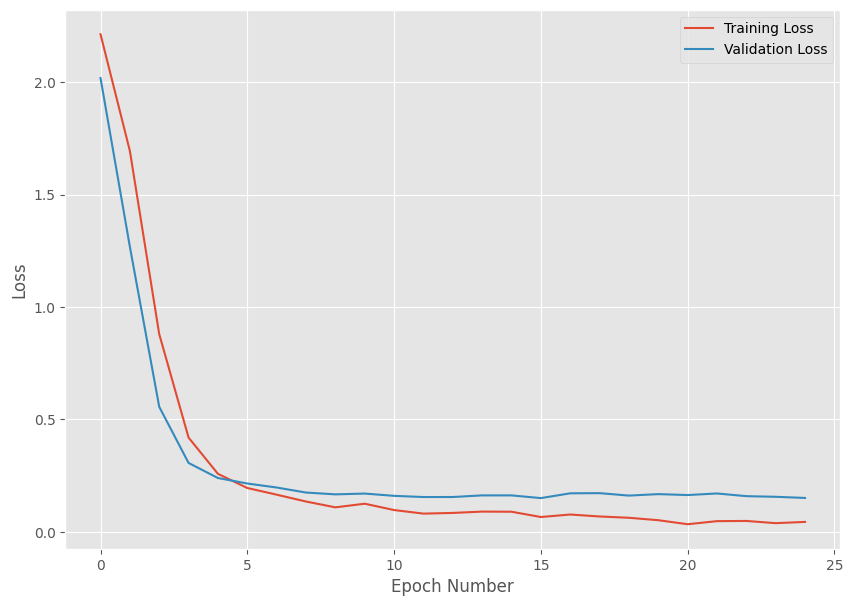

In [16]:
plt.figure(figsize=(10, 7))
history = np.array(history)
plt.plot(history[:,0:2])
plt.legend(['Training Loss', 'Validation Loss'])
plt.xlabel('Epoch Number')
plt.ylabel('Loss')
plt.savefig('loss_curve.png')
plt.show()

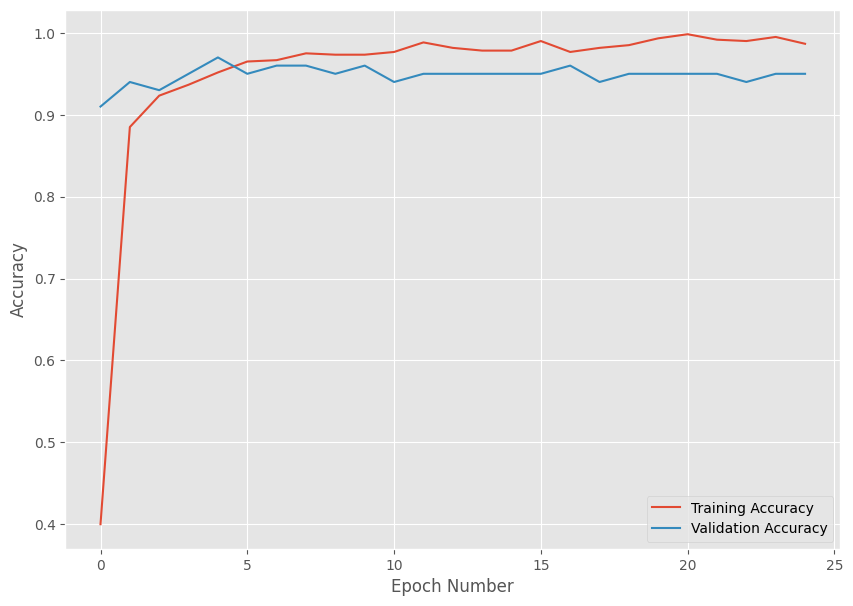

In [17]:
plt.figure(figsize=(10, 7))
plt.plot(history[:,2:4])
plt.legend(['Training Accuracy', 'Validation Accuracy'])
plt.xlabel('Epoch Number')
plt.ylabel('Accuracy')
plt.savefig('accuracy_curve.png')
plt.show()